In [ ]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

def samme_round(X, y, w, depth, K, seed=0, eps_floor=1e-10):
    """One SAMME round. Returns (learner, predictions, eps, alpha, new_weights, status)."""
    h = DecisionTreeClassifier(max_depth=depth, random_state=seed).fit(X, y, sample_weight=w)
    pred = h.predict(X)
    miss = pred != y
    eps = w[miss].sum()
    if eps >= 1 - 1 / K:                      # not better than random guessing
        return h, pred, eps, None, w, "rejected"
    eps_c = max(eps, eps_floor)               # avoid log(inf) for a perfect learner
    alpha = np.log((1 - eps_c) / eps_c) + np.log(K - 1)
    w_new = w * np.exp(alpha * miss)
    w_new = w_new / w_new.sum()
    return h, pred, eps, alpha, w_new, "ok"

# toy data: 9 samples, 1 feature, 3 classes
X = np.arange(1, 10, dtype=float).reshape(-1, 1)
y = np.array([0, 0, 1, 0, 1, 1, 2, 2, 1])
K = 3
w = np.full(len(y), 1 / len(y))

h, pred, eps, alpha, w_new, status = samme_round(X, y, w, depth=1, K=K)
np.set_printoptions(precision=4, suppress=True)
print("true labels      :", y)
print("initial weights  :", w)
print("weak learner pred:", pred)
print("misclassified    :", (pred != y).astype(int))
print("weighted error   :", round(eps, 4), "| status:", status)
print("alpha            :", None if alpha is None else round(alpha, 4))
print("updated weights  :", w_new, "| sum =", w_new.sum())

true labels      : [0 0 1 0 1 1 2 2 1]
initial weights  : [0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111]
weak learner pred: [0 0 0 0 1 1 1 1 1]
misclassified    : [0 0 1 0 0 0 1 1 0]
weighted error   : 0.3333 | status: ok
alpha            : 1.3863
updated weights  : [0.0556 0.0556 0.2222 0.0556 0.0556 0.0556 0.2222 0.2222 0.0556] | sum = 1.0


In [ ]:
import json, time, pickle, pandas as pd
from sklearn.datasets import fetch_olivetti_faces

d = fetch_olivetti_faces()
X_all, y_all = d.data, d.target
s = np.load("split.npz")          # upload split.npz to this notebook first
tr, va, te = s["tr"], s["va"], s["te"]
Xtr, ytr = X_all[tr], y_all[tr]
Xva, yva = X_all[va], y_all[va]
Xte, yte = X_all[te], y_all[te]

def mask(Xs):
    Xm = Xs.copy().reshape(-1, 64, 64)
    Xm[:, 24:40, 24:40] = 0
    return Xm.reshape(len(Xs), -1)
Xte_m = mask(Xte)
K = 40
print(Xtr.shape, Xva.shape, Xte.shape)

(240, 4096) (80, 4096) (80, 4096)


In [ ]:
def samme_fit(X, y, depth, T, K=40):
    n = len(X); w = np.full(n, 1 / n)
    learners, alphas, hist, W, M = [], [], [], [], []
    for t in range(T):
        h, pred, eps, alpha, w_new, status = samme_round(X, y, w, depth, K, seed=t)
        if status == "rejected":
            print(f"depth {depth}: round {t+1} rejected (eps={eps:.3f} >= {1-1/K:.3f}), stopping")
            break
        W.append(w.copy()); M.append(pred != y)      # weights used and mistakes this round
        learners.append(h); alphas.append(alpha)
        w = w_new
        hist.append(dict(round=t + 1, eps=eps, alpha=alpha,
                         wmax=w.max(), top10=np.sort(w)[-10:].sum()))
        if eps <= 1e-10:                              # perfect learner, stop
            print(f"depth {depth}: perfect learner at round {t+1}, stopping")
            break
    return learners, np.array(alphas), hist, np.array(W), np.array(M)

def samme_q(learners, alphas, X, T, K=40):
    """Normalised weighted vote q_k(x) using the first T learners."""
    S = np.zeros((len(X), K))
    for h, a in zip(learners[:T], alphas[:T]):
        S[np.arange(len(X)), h.predict(X)] += a
    return S / alphas[:T].sum()

In [ ]:
models, rows = {}, []
for depth in [1, 2, 3, 4]:
    t0 = time.time()
    models[depth] = samme_fit(Xtr, ytr, depth, T=100)
    train_time = time.time() - t0
    L, A = models[depth][0], models[depth][1]
    for T in [10, 25, 50, 100]:
        if T > len(L):
            continue                                   # stopped before T rounds
        rows.append(dict(depth=depth, rounds=T,
                         train=(samme_q(L, A, Xtr, T).argmax(1) == ytr).mean(),
                         val=(samme_q(L, A, Xva, T).argmax(1) == yva).mean(),
                         test=(samme_q(L, A, Xte, T).argmax(1) == yte).mean(),
                         rounds_trained=len(L), time_100=round(train_time, 1)))
dfs = pd.DataFrame(rows)
print(dfs.round(3).to_string())

# tie-break: highest val, then fewest rounds, then smallest depth
best = dfs.sort_values(["val", "rounds", "depth"], ascending=[False, True, True]).iloc[0]
print("\nSELECTED:\n", best)
dfs.to_csv("q2b_results.csv", index=False)
json.dump({"depth": int(best.depth), "rounds": int(best.rounds)}, open("frozen_boost.json", "w"))
pickle.dump(models, open("boost_models.pkl", "wb"))

    depth  rounds  train    val   test  rounds_trained  time_100
0       1      10  0.050  0.025  0.038             100      11.6
1       1      25  0.092  0.062  0.062             100      11.6
2       1      50  0.267  0.112  0.212             100      11.6
3       1     100  0.208  0.138  0.150             100      11.6
4       2      10  0.108  0.038  0.075             100      24.5
5       2      25  0.288  0.175  0.200             100      24.5
6       2      50  0.233  0.088  0.138             100      24.5
7       2     100  0.267  0.075  0.100             100      24.5
8       3      10  0.288  0.112  0.150             100      33.1
9       3      25  0.471  0.200  0.250             100      33.1
10      3      50  0.658  0.188  0.262             100      33.1
11      3     100  0.804  0.288  0.362             100      33.1
12      4      10  0.300  0.125  0.175             100      43.0
13      4      25  0.633  0.238  0.262             100      43.0
14      4      50  0.625 

In [ ]:
H = pd.DataFrame(models[4][2])
print(H[["eps", "alpha", "wmax", "top10"]].describe().round(3))

           eps    alpha     wmax    top10
count  100.000  100.000  100.000  100.000
mean     0.669    2.947    0.048    0.275
std      0.054    0.264    0.018    0.081
min      0.460    1.876    0.005    0.048
25%      0.644    2.872    0.037    0.226
50%      0.670    2.956    0.050    0.275
75%      0.688    3.071    0.061    0.339
max      0.857    3.824    0.087    0.421


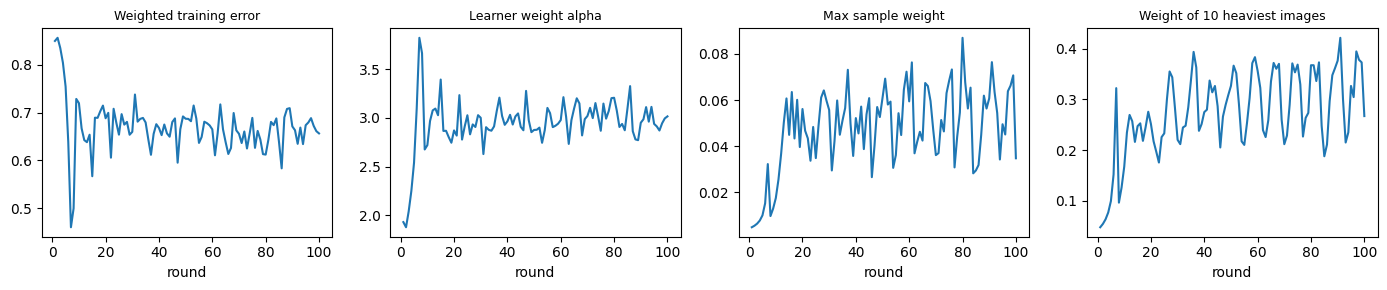

In [ ]:
import matplotlib.pyplot as plt
dep, Tsel = int(best.depth), int(best.rounds)
H = pd.DataFrame(models[dep][2]).iloc[:Tsel]
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, col, title in zip(ax, ["eps", "alpha", "wmax", "top10"],
        ["Weighted training error", "Learner weight alpha", "Max sample weight", "Weight of 10 heaviest images"]):
    a.plot(H["round"], H[col]); a.set_title(title, fontsize=9); a.set_xlabel("round")
plt.tight_layout(); plt.savefig("q2b_diagnostics.png", dpi=200); plt.show()

In [ ]:
frozen_t = json.load(open("frozen_tree.json"))
frozen_b = json.load(open("frozen_boost.json"))
params = dict(max_depth=frozen_t["depth"], min_samples_leaf=frozen_t["min_samples_leaf"])
depth_b = frozen_b["depth"]
n = len(Xtr)

ROLL = "M26ECM505"                         # same roll number as Q1
SEED = int("".join(c for c in ROLL if c.isdigit()))

def bag_acc(trees, Xs, ys, B):
    V = np.zeros((len(Xs), K))
    for t in trees[:B]:
        V[np.arange(len(Xs)), t.predict(Xs)] += 1
    return (V.argmax(1) == ys).mean()

rows = []

# ---- bagging: same seed and call order as Q1, so these are the same trees as Q1 ----
rng = np.random.default_rng(SEED)
trees, cum, t0 = [], {}, time.time()
for b in range(100):
    idx = rng.integers(0, n, n)
    t = DecisionTreeClassifier(**params, random_state=int(rng.integers(1_000_000_000)))
    t.fit(Xtr[idx], ytr[idx])
    trees.append(t)
    if b + 1 in (25, 50, 100):
        cum[b + 1] = time.time() - t0      # training time only, evaluation comes later
for B in [25, 50, 100]:
    rows.append(dict(model="bagging", learners=B,
                     train=bag_acc(trees, Xtr, ytr, B), val=bag_acc(trees, Xva, yva, B),
                     test=bag_acc(trees, Xte, yte, B), train_time_s=round(cum[B], 1)))

# ---- boosting: same SAMME code, depth frozen in Q2(b) ----
for T in [25, 50, 100]:
    t0 = time.time()
    L, A, hist, W, M = samme_fit(Xtr, ytr, depth_b, T)
    tt = time.time() - t0
    if T == 100:
        boost100 = (L, A, hist, W, M)
    rows.append(dict(model="boosting", learners=T,
                     train=(samme_q(L, A, Xtr, T).argmax(1) == ytr).mean(),
                     val=(samme_q(L, A, Xva, T).argmax(1) == yva).mean(),
                     test=(samme_q(L, A, Xte, T).argmax(1) == yte).mean(),
                     train_time_s=round(tt, 1)))

dfc2 = pd.DataFrame(rows)
print(dfc2.round(3).to_string())
dfc2.to_csv("q2c_results.csv", index=False)

      model  learners  train    val   test  train_time_s
0   bagging        25  1.000  0.812  0.800          34.8
1   bagging        50  1.000  0.812  0.850          68.3
2   bagging       100  1.000  0.875  0.862         135.5
3  boosting        25  0.633  0.238  0.262          11.0
4  boosting        50  0.625  0.225  0.288          22.2
5  boosting       100  1.000  0.325  0.400          44.6


training face index: 209 | true class: 34
uniform weight would be 0.0042, this face reached 0.0870 at round 81
misclassified in 88 of 100 rounds
most common wrong predictions (class, count): [(14, 11), (3, 10), (12, 8)]
history, first 40 rounds (1 = wrong): [1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
5 heaviest faces and how often each was wrong: [(209, 88), (47, 87), (70, 87), (34, 87), (60, 87)]


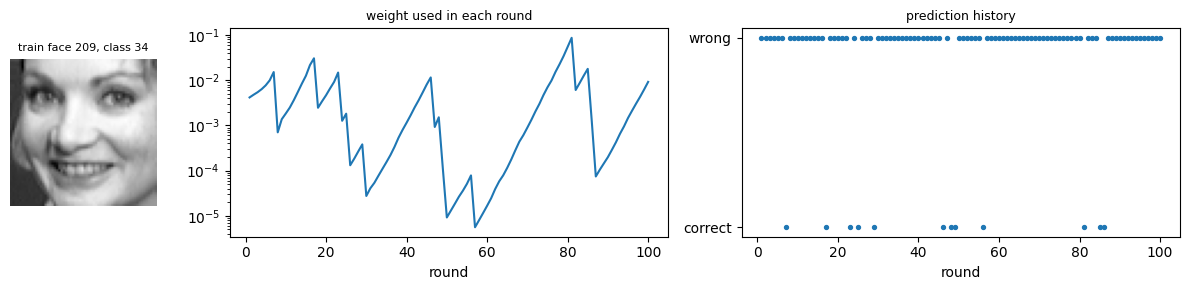

In [ ]:
L, A, hist, W, M = boost100        # W[t, i] = weight of face i used in round t; M[t, i] = wrong in round t
i = int(W.max(axis=0).argmax())    # face that reaches the largest weight at any round
print("training face index:", i, "| true class:", ytr[i])
print("uniform weight would be %.4f, this face reached %.4f at round %d"
      % (1 / n, W[:, i].max(), W[:, i].argmax() + 1))
print("misclassified in %d of %d rounds" % (M[:, i].sum(), len(M)))

hist_pred = np.array([h.predict(Xtr[i:i+1])[0] for h in L])
vals, counts = np.unique(hist_pred[hist_pred != ytr[i]], return_counts=True)
print("most common wrong predictions (class, count):",
      sorted(zip(vals.tolist(), counts.tolist()), key=lambda x: -x[1])[:3])
print("history, first 40 rounds (1 = wrong):", M[:40, i].astype(int).tolist())

top5 = np.argsort(W.max(axis=0))[::-1][:5]
print("5 heaviest faces and how often each was wrong:", [(int(j), int(M[:, j].sum())) for j in top5])

fig, ax = plt.subplots(1, 3, figsize=(12, 3), gridspec_kw={"width_ratios": [1, 3, 3]})
ax[0].imshow(Xtr[i].reshape(64, 64), cmap="gray"); ax[0].axis("off")
ax[0].set_title(f"train face {i}, class {ytr[i]}", fontsize=8)
r = np.arange(1, len(W) + 1)
ax[1].semilogy(r, W[:, i]); ax[1].set_title("weight used in each round", fontsize=9); ax[1].set_xlabel("round")
ax[2].scatter(r, M[:, i].astype(int), s=8); ax[2].set_yticks([0, 1]); ax[2].set_yticklabels(["correct", "wrong"])
ax[2].set_title("prediction history", fontsize=9); ax[2].set_xlabel("round")
plt.tight_layout(); plt.savefig("q2c_heavy_face.png", dpi=200); plt.show()

In [ ]:
tree0 = DecisionTreeClassifier(**params, random_state=0).fit(Xtr, ytr)   # same as Q1
Lb, Ab = boost100[0], boost100[1]
T_B, B = frozen_b["rounds"], 100

def tree_out(Xs):
    p = tree0.predict_proba(Xs)
    return p.argmax(1), p.max(1)

def bag_out(Xs):
    preds = np.array([t.predict(Xs) for t in trees[:B]])       # (B, N)
    V = np.zeros((len(Xs), K))
    for b in range(B):
        V[np.arange(len(Xs)), preds[b]] += 1
    return V.argmax(1), V.max(1) / B, V, preds

def boost_out(Xs):
    q = samme_q(Lb, Ab, Xs, T_B)
    return q.argmax(1), q.max(1), q

out = {}
rows = []
for name, Xs in [("clean", Xte), ("masked", Xte_m)]:
    tp, tc = tree_out(Xs)
    bp, bc, Vb, Pb = bag_out(Xs)
    sp, sc, Q = boost_out(Xs)
    out[name] = dict(tp=tp, bp=bp, sp=sp, Vb=Vb, Pb=Pb, Q=Q)
    rows.append(dict(test_set=name,
                     tree_acc=(tp == yte).mean(), tree_conf=tc.mean(),
                     bag_acc=(bp == yte).mean(), bag_conf=bc.mean(),
                     boost_acc=(sp == yte).mean(), boost_conf=sc.mean()))
dfd2 = pd.DataFrame(rows)
print(dfd2.round(3).to_string())
dfd2.to_csv("q2d_results.csv", index=False)

  test_set  tree_acc  tree_conf  bag_acc  bag_conf  boost_acc  boost_conf
0    clean     0.575      0.968    0.862     0.390      0.400       0.123
1   masked     0.175      1.000    0.838     0.297      0.375       0.122


bagging right on both, boosting right clean but wrong masked: 1
chosen test face: 39 | true class: 19
clean : tree 19 bag 19 boost 19
masked: tree 19 bag 19 boost 14
bagging clean: votes for true class 62/100, winner 19 with 62, disagreement 0.608
bagging masked: votes for true class 49/100, winner 19 with 49, disagreement 0.747
fraction of bagged trees whose prediction changed under the mask: 0.27
boosting clean: q(true class) 0.126, winner 19 with q 0.126
boosting masked: q(true class) 0.115, winner 14 with q 0.122
fraction of alpha mass on learners whose prediction changed: 0.011
changed learners, rounds 1-50 vs 51-100: 0 1
split pixels inside block | single tree: 0.05 | bagged trees: 0.06 | boosting stumps: 0.043 | block covers 0.0625 of pixels


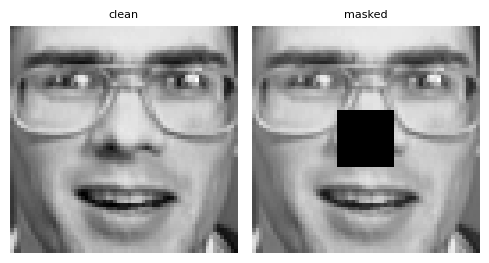

In [ ]:
c, m = out["clean"], out["masked"]
bag_c, bag_m = c["bp"] == yte, m["bp"] == yte
bst_c, bst_m = c["sp"] == yte, m["sp"] == yte

cand = np.where(bag_c & bag_m & bst_c & ~bst_m)[0]    # bagging robust, boosting breaks
print("bagging right on both, boosting right clean but wrong masked:", len(cand))
if len(cand) == 0:
    cand = np.where(bag_m != bst_m)[0]                 # fallback: any difference on masked
    print("fallback: faces where bagging and boosting differ on masked:", len(cand))
i = int(cand[0])
print("chosen test face:", i, "| true class:", yte[i])
print("clean : tree", c["tp"][i], "bag", c["bp"][i], "boost", c["sp"][i])
print("masked: tree", m["tp"][i], "bag", m["bp"][i], "boost", m["sp"][i])

# ---- bagging: tree disagreement on this face ----
def disagreement(votes, B):
    return 1 - (votes * (votes - 1)).sum() / (B * (B - 1))   # prob. two trees differ
for name, o in [("clean", c), ("masked", m)]:
    V = o["Vb"][i]
    print(f"bagging {name}: votes for true class {int(V[yte[i]])}/{B}, "
          f"winner {int(V.argmax())} with {int(V.max())}, disagreement {disagreement(V, B):.3f}")
changed = (c["Pb"][:, i] != m["Pb"][:, i]).mean()
print("fraction of bagged trees whose prediction changed under the mask:", round(changed, 3))

# ---- boosting: weighted vote on this face ----
for name, o in [("clean", c), ("masked", m)]:
    q = o["Q"][i]
    print(f"boosting {name}: q(true class) {q[yte[i]]:.3f}, winner {int(q.argmax())} with q {q.max():.3f}")
pc = np.array([h.predict(Xte[i:i+1])[0] for h in Lb[:T_B]])
pm = np.array([h.predict(Xte_m[i:i+1])[0] for h in Lb[:T_B]])
ch = pc != pm
print("fraction of alpha mass on learners whose prediction changed:", round(Ab[:T_B][ch].sum() / Ab[:T_B].sum(), 3))
print("changed learners, rounds 1-50 vs 51-100:", int(ch[:50].sum()), int(ch[50:].sum()))

# ---- do the split pixels fall inside the masked block? ----
def in_block(f):
    r, cc = divmod(f, 64)
    return 24 <= r <= 39 and 24 <= cc <= 39
def frac_in_block(t):
    feats = t.tree_.feature[t.tree_.feature >= 0]
    return np.mean([in_block(f) for f in feats])
print("split pixels inside block | single tree:", round(frac_in_block(tree0), 3),
      "| bagged trees:", round(np.mean([frac_in_block(t) for t in trees[:B]]), 3),
      "| boosting stumps:", round(np.mean([frac_in_block(h) for h in Lb[:T_B]]), 3),
      "| block covers 0.0625 of pixels")

fig, ax = plt.subplots(1, 2, figsize=(5, 2.8))
ax[0].imshow(Xte[i].reshape(64, 64), cmap="gray"); ax[0].set_title("clean", fontsize=8)
ax[1].imshow(Xte_m[i].reshape(64, 64), cmap="gray"); ax[1].set_title("masked", fontsize=8)
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("q2d_face.png", dpi=200); plt.show()